## CAMulator Westerlies Push ice south twoards the coast of norway, this notebook will check the ice stress and wind stress terms to validiate this feedback. 


**Load the ck70 checkpoint for 1980 to 2015**

**Mask the barnet sea for this experiment**


In [15]:
%matplotlib inline
from ice_ens import stress, data, plot_poles

CASE    = "ck70"
YEARS   = (1980, 2015)                  # inclusive
FIG_DIR = data.out_dir(CASE, "stress")  # -> output/ck70/stress/

# Barents box, editable: stress.BARENTS = {"lat": (70, 80), "lon": (15, 60)}
stress.BARENTS

{'lat': (70.0, 80.0), 'lon': (15.0, 60.0)}

**Build the cache (once).** Reads TAUX/TAUY from POP and aice/strairx/strairy from CICE for every month, keeps rows north of ~38N.
~3 min for 36 years, written to `/glade/derecho/scratch/tvoeller/honors_thesis/stress_cache/ck70/`. Re-running skips years already there.

In [16]:
stress.build_stress_cache(CASE, YEARS)

**Load.** TAUX/TAUY are converted dyne/cm² → N/m². All four components are on the U-grid along grid-x/y, so they are rotated with the U-grid `ANGLE` into
`TAU_E, TAU_N` (POP) and `STRAIR_E, STRAIR_N` (CICE). `ANGLET` would only be needed for T-grid vectors.

In [17]:
ds = stress.load_stress(CASE, YEARS)
ds

<xarray.Dataset> Size: 749MB
Dimensions:   (time: 432, nj: 104, ni: 320)
Coordinates:
  * time      (time) object 3kB 1980-01-15 00:00:00 ... 2015-12-15 00:00:00
    year      (time) int32 2kB 1980 1980 1980 1980 1980 ... 2015 2015 2015 2015
    month     (time) int32 2kB 1 2 3 4 5 6 7 8 9 10 ... 3 4 5 6 7 8 9 10 11 12
    ULAT      (nj, ni) float32 133kB 30.6 30.61 30.61 ... 72.42 72.41 72.41
    ULON      (nj, ni) float32 133kB 321.1 322.2 323.3 ... 319.2 319.6 320.0
    TLAT      (nj, ni) float32 133kB 30.38 30.38 30.38 ... 72.2 72.19 72.19
    TLON      (nj, ni) float32 133kB 320.6 321.7 322.8 ... 318.9 319.4 319.8
Dimensions without coordinates: nj, ni
Data variables: (12/18)
    TAUX      (time, nj, ni) float32 58MB -0.02592 -0.0283 -0.03032 ... nan nan
    TAUY      (time, nj, ni) float32 58MB 0.009258 0.005865 0.002428 ... nan nan
    aice      (time, nj, ni) float32 58MB 0.0 0.0 0.0 0.0 ... nan nan nan nan
    strairx   (time, nj, ni) float32 58MB 0.0 0.0 0.0 0.0 ... nan nan nan nan
    strairy   (time, nj, ni) float32 58MB 0.0 0.0 0.0 0.0 ... nan nan nan nan
    uatm      (time, nj, ni) float32 58MB -2.525 -2.749 -2.954 ... nan nan nan
    ...        ...
    TAU_E     (time, nj, ni) float32 58MB -0.02593 -0.02831 -0.03032 ... nan nan
    TAU_N     (time, nj, ni) float32 58MB 0.009233 0.005811 0.00234 ... nan nan
    STRAIR_E  (time, nj, ni) float32 58MB 0.0 0.0 0.0 0.0 ... nan nan nan nan
    STRAIR_N  (time, nj, ni) float32 58MB 0.0 0.0 0.0 0.0 ... nan nan nan nan
    WIND_E    (time, nj, ni) float32 58MB -2.527 -2.752 -2.957 ... nan nan nan
    WIND_N    (time, nj, ni) float32 58MB 1.529 1.244 0.9488 ... nan nan nan
Attributes:
    case:     ck70

**Arctic: aice shaded, stress vectors on top, Barents box in gold.** Change `months` for other seasons, e.g. `[3]`, `[6, 7, 8]`, `[9, 10, 11]`.

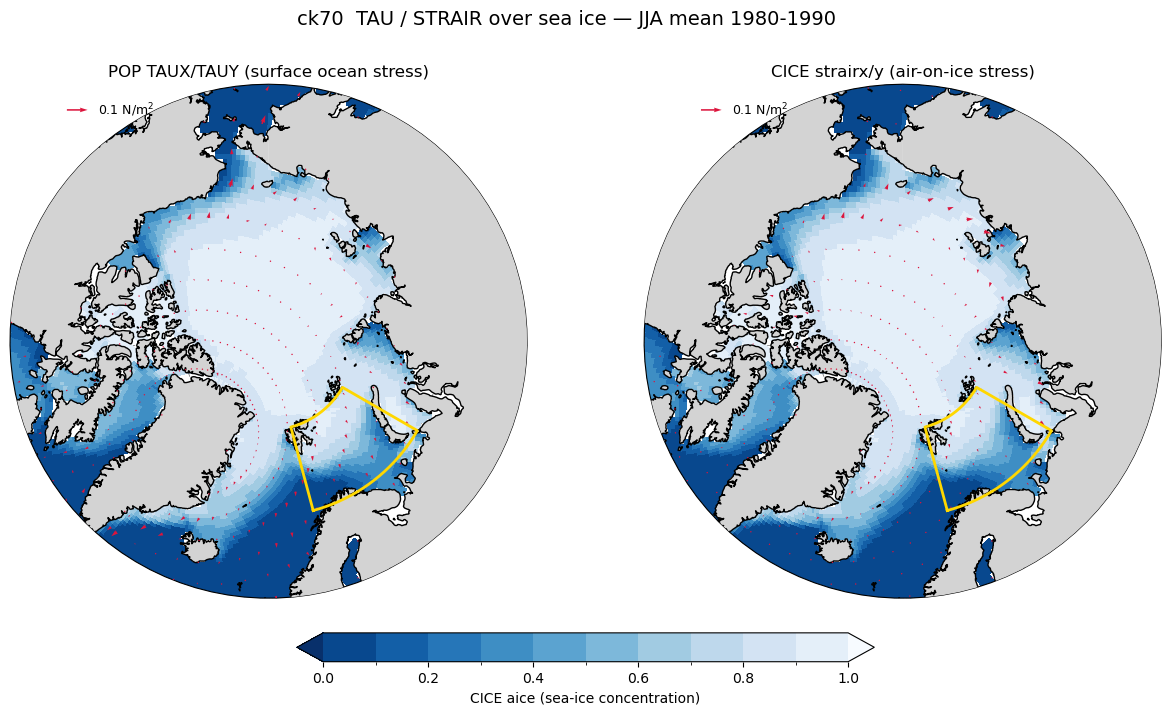

In [10]:
fig = stress.plot_stress_map(ds, months=[6,7,8], fig_dir=FIG_DIR)

**Barents Sea only, vectors masked to the box (ocean cells only).**

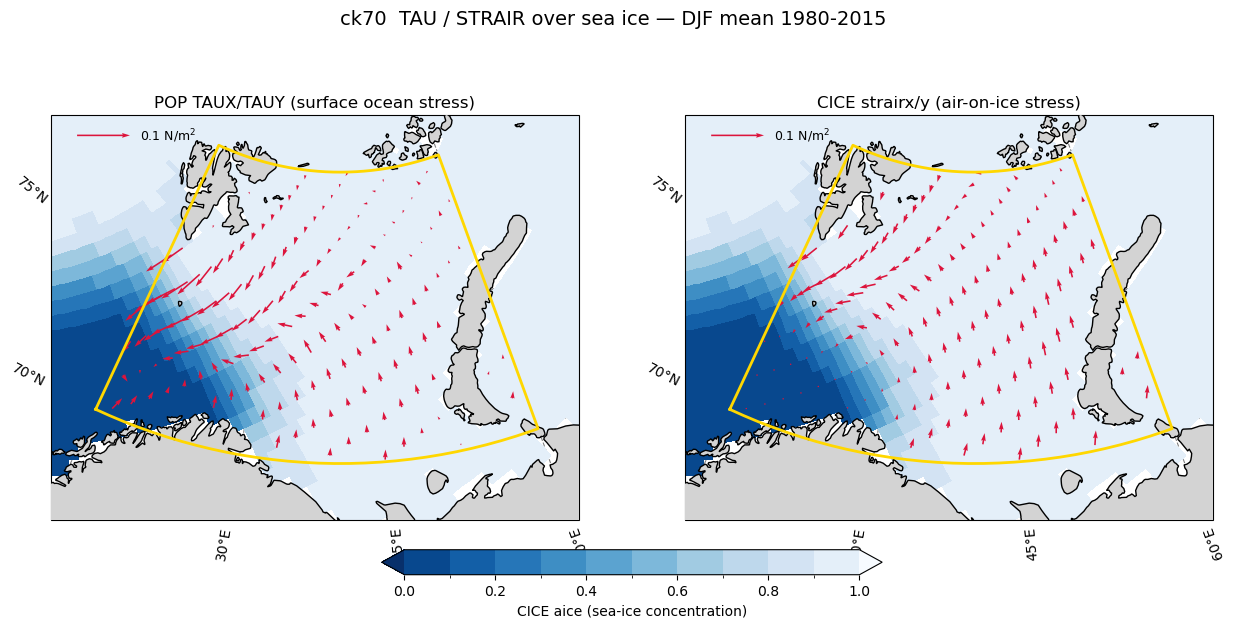

In [5]:
fig = stress.plot_stress_map(ds, months=[12, 1, 2], zoom=True, fig_dir=FIG_DIR)

**Barents-mean stress and aice, one value per year.** Area-weighted (`uarea` for stress, `tarea` for aice). Negative northward = southward, toward Norway.

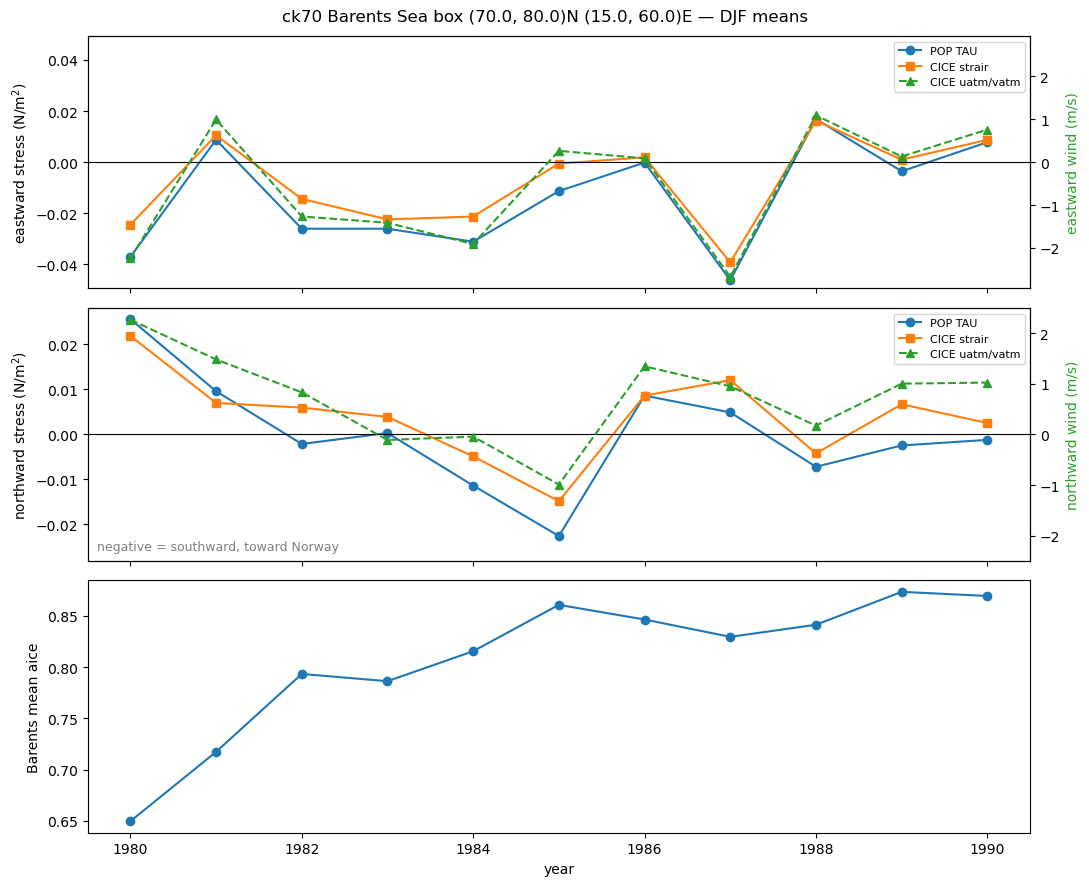

In [11]:
series = stress.barents_series(ds)
fig = stress.plot_barents_series(series, months=[12, 1, 2], label=CASE, fig_dir=FIG_DIR)

In [7]:
# Mean seasonal cycle over the Barents box, 1980-2015
series.groupby("month").mean("time").to_dataframe().round(4)

,TAU_E,TAU_N,STRAIR_E,STRAIR_N,WIND_E,WIND_N,aice
month,,,,,,,
1,-0.0110,0.0005,-0.0069,0.0060,-0.4076,0.7322,0.8430
2,-0.0092,0.0087,-0.0044,0.0159,-0.2199,1.5270,0.8450
3,-0.0105,-0.0022,-0.0010,0.0007,-0.0794,0.4956,0.8442
4,-0.0082,-0.0144,-0.0012,-0.0107,0.0646,-0.4458,0.8444
5,-0.0131,-0.0121,-0.0073,-0.0109,-0.6228,-0.7519,0.8031
6,-0.0152,-0.0165,-0.0091,-0.0148,-1.0258,-1.5438,0.7052
7,-0.0106,-0.0144,-0.0058,-0.0100,-0.7523,-0.9995,0.5754
8,-0.0054,-0.0079,-0.0033,-0.0035,-0.4276,-0.2145,0.4619
9,0.0104,-0.0171,0.0058,-0.0088,1.1503,-0.7092,0.4559


## Does the wind direction match the wind stress?

`uatm`/`vatm` is CICE's lowest-level atmospheric wind, on the same corner grid and grid-x/y axes as `strairx`/`strairy`, so it is rotated with the same `ANGLE` into `WIND_E, WIND_N`.
It is defined everywhere, ice or not. The cache must include it: if `load_stress` complains, run `stress.build_stress_cache(CASE, YEARS, force=True)` once.

**Barents box: stress next to the wind.** Arrow lengths are per panel (N/m² vs m/s); compare directions.

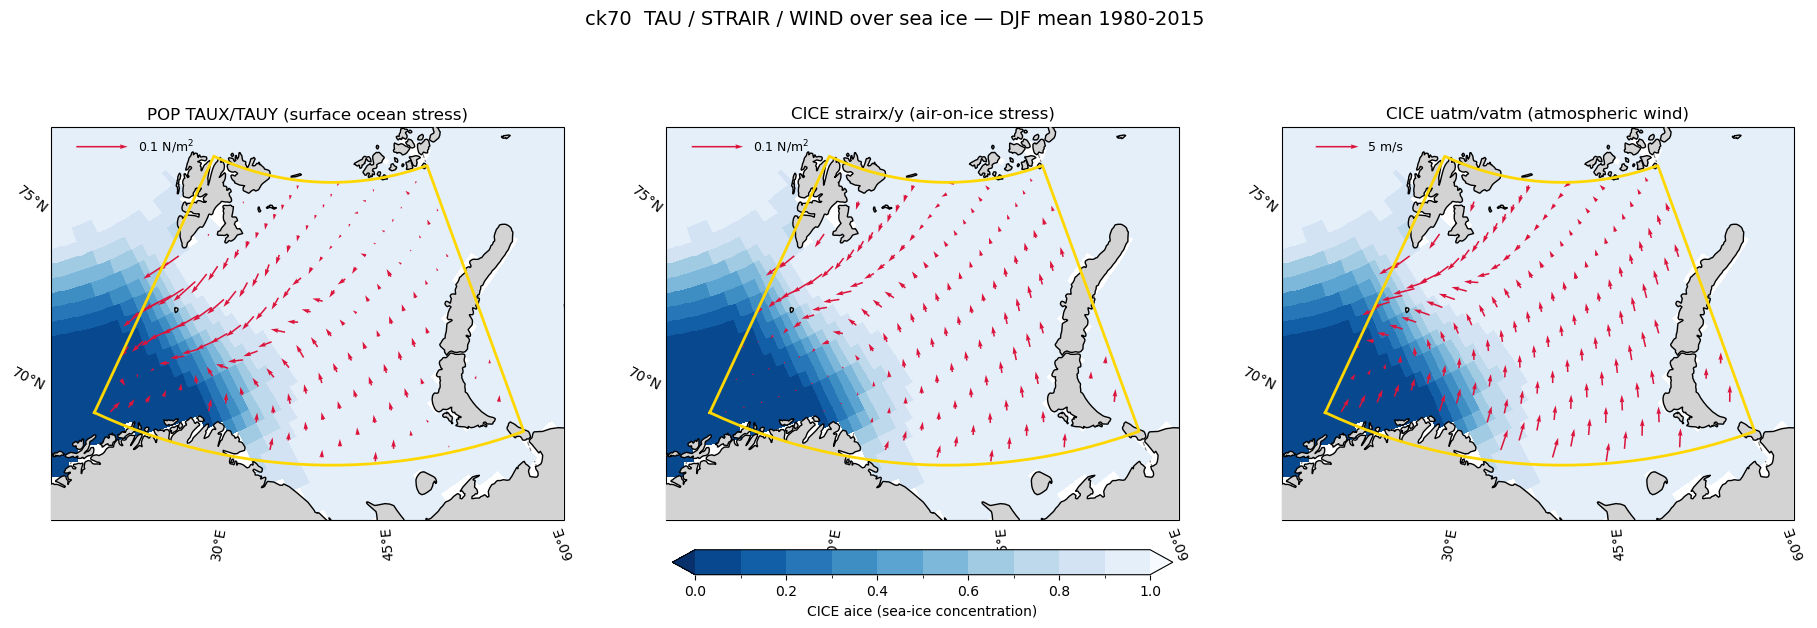

In [8]:
fig = stress.plot_stress_map(ds, months=[12, 1, 2], zoom=True, panels=("TAU", "STRAIR", "WIND"), fig_dir=FIG_DIR)

**Year to year.** The series figure above now also shows the wind on a right-hand axis (green), with zero aligned to the stress zero, so sign agreement reads straight off.

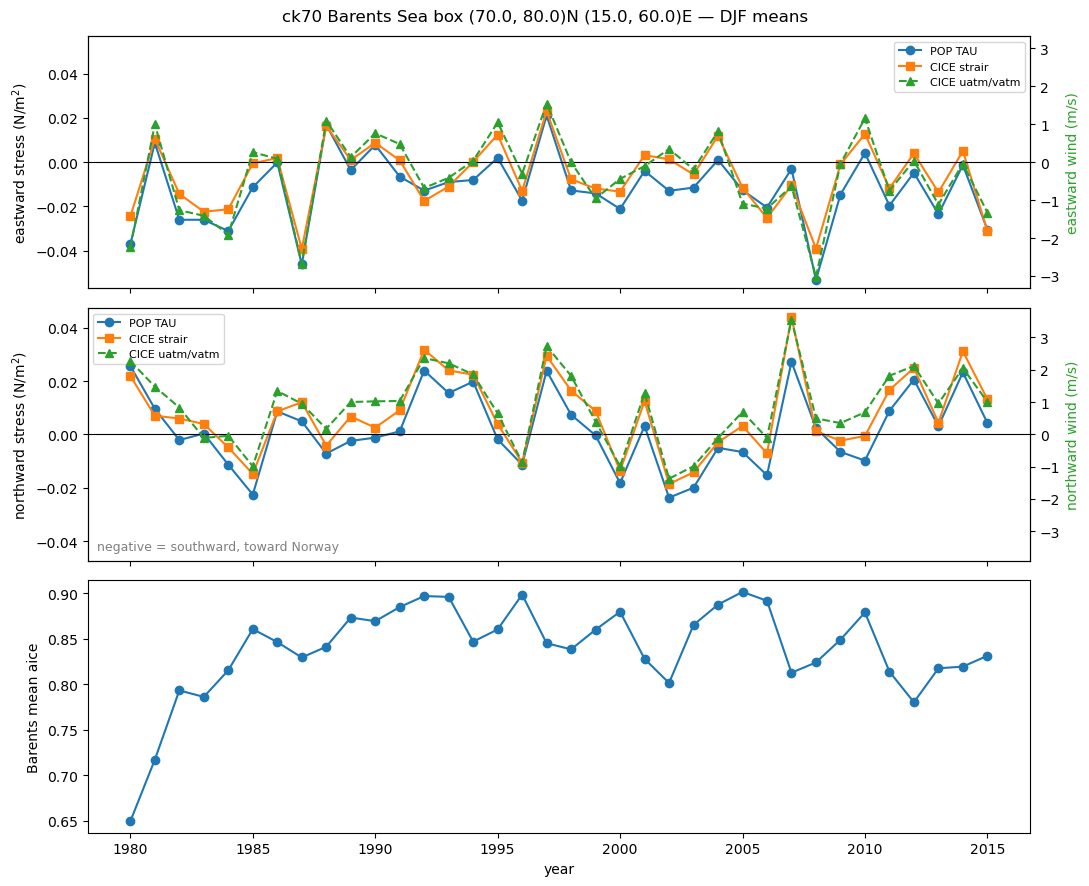

In [9]:
fig = stress.plot_barents_series(series, months=[12, 1, 2], label=CASE)

**Direction table.** Compass direction each Barents-mean vector points *toward* (0 = N, 90 = E, 180 = S; this is the opposite of the meteorological "from" convention).
`*_minus_wind` is the stress direction minus the wind direction, in degrees (positive = stress turned clockwise of the wind).
Read it alongside `wind_speed_mean_vector`: when the mean vector wind is under ~1 m/s, the direction is not well defined and large offsets mean little.

In [10]:
stress.wind_vs_stress(series)            # mean seasonal cycle

,wind_speed_mean_vector,WIND_dir,TAU_dir,STRAIR_dir,TAU_minus_wind,STRAIR_minus_wind
month,,,,,,
1,0.8,330.9,272.5,311.0,-58.4,-19.9
2,1.5,351.8,313.4,344.6,-38.4,-7.2
3,0.5,350.9,258.1,303.8,-92.8,-47.1
4,0.5,171.7,209.8,186.2,38.0,14.5
5,1.0,219.6,227.4,213.6,7.7,-6.0
6,1.9,213.6,222.6,211.7,9.0,-1.9
7,1.3,217.0,216.4,210.1,-0.6,-6.8
8,0.5,243.4,214.1,222.6,-29.2,-20.8
9,1.4,121.7,148.7,146.6,27.0,25.0


In [11]:
stress.wind_vs_stress(series, [12, 1, 2]) # DJF pooled

,wind_speed_mean_vector,WIND_dir,TAU_dir,STRAIR_dir,TAU_minus_wind,STRAIR_minus_wind
months,,,,,,
DJF,0.9,337.5,278.8,319.3,-58.7,-18.2


## Stress over the ice bias against CESM

Same arrows, but the shading is now the climatological sea-ice bias, **ck70 `IFRAC` − CESM `ICEFRAC`** (red = ck70 has too much ice), exactly as in `ice_comparison.ipynb` / `ice_climatology.ipynb`:
the CESM reference `ICEFRAC` is regridded conservatively onto gx1v7 with the saved weights in `weights/`.

- CAMulator's own output has no `ICEFRAC` (sea ice comes from CICE), so the ck70 side is POP's coupler `IFRAC`.
- **The CESM reference stops at 2014**, so the bias, and the arrows on these maps, are 1980–2014.
- Coastal cells carry a small spurious *positive* bias from CAM's land dilution of `ICEFRAC` (see README "Things to mention", #1). Interior ocean is unaffected.

About 1.5 min per season: it averages 35 years of 6-hourly CESM zarrs.

In [18]:
from ice_ens import bias_ensemble

BIAS_MONTHS = [12, 1, 2]
biases, areas = bias_ensemble(
    {CASE: f"{data.CASE_ROOT}/{data.case_name(CASE)}/run"},
    reference_path=f"{data.TRUTH_ROOT}/" + data.TRUTH_TEMPLATE.format(year="*"),
    months=BIAS_MONTHS, years=(1980, 2014), hemisphere="north", ref_var="ICEFRAC",
    weights_path=f"{data.WEIGHT_DIR}/conservative_ref192x288_to_gx1v7_384x320.nc",
)
bias = biases[CASE]

reference  ICEFRAC  12600 timesteps, 1980-2014 months [12, 1, 2]: north ice area 12.597 x10^6 km2


KeyboardInterrupt: 

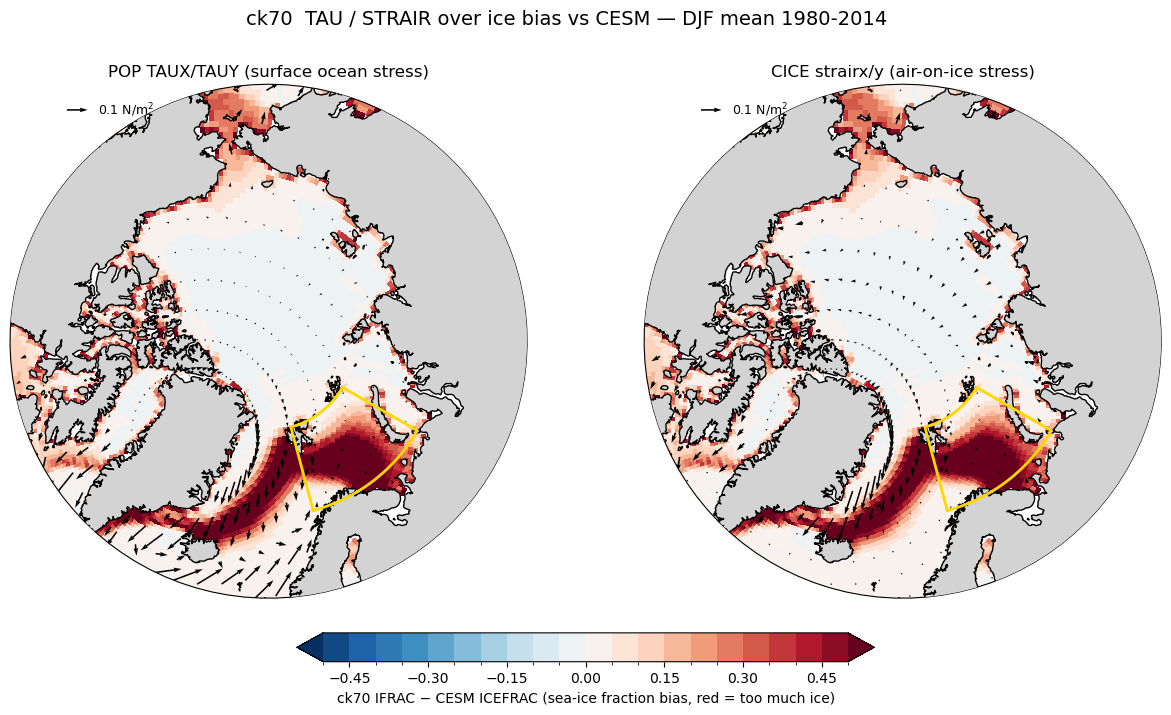

In [13]:
fig = stress.plot_stress_map(ds, months=BIAS_MONTHS, bias=bias, fig_dir=FIG_DIR)

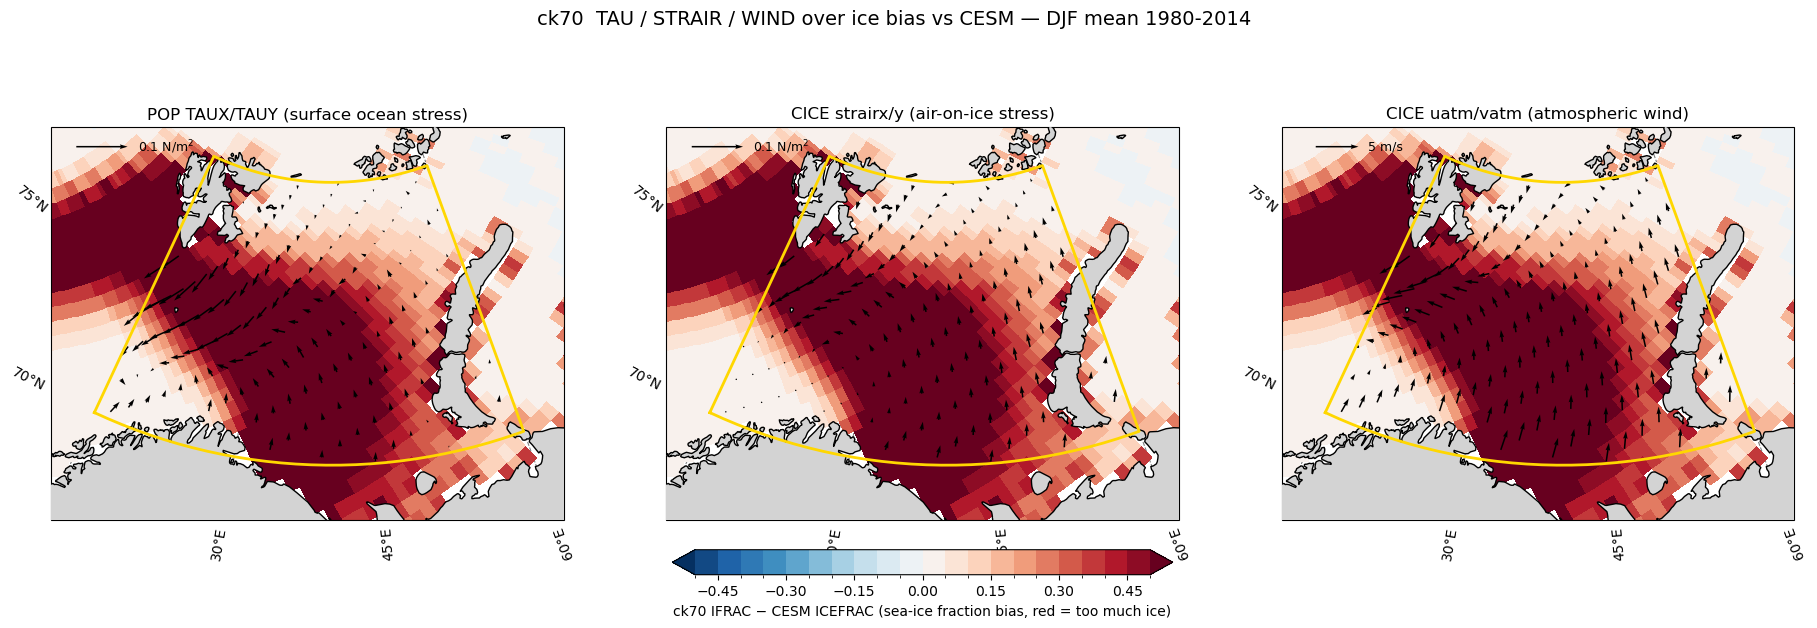

In [14]:
fig = stress.plot_stress_map(ds, months=BIAS_MONTHS, zoom=True, panels=("TAU", "STRAIR", "WIND"), bias=bias, fig_dir=FIG_DIR)

In [19]:
# Barents-box mean bias (area-weighted, ocean cells only)
b = bias.isel(nlat=slice(stress.J0, None)).rename(nlat="nj", nlon="ni")
m = stress.barents_mask(ds.isel(time=0), "T")
print(f"Barents mean {''.join(plot_poles.MONTH_NAMES[k-1][0] for k in BIAS_MONTHS)} ice-fraction bias: "
      f"{float(b.where(m).weighted(ds['tarea'].where(m, 0)).mean()):+.3f}")

NameError: name 'bias' is not defined

## Atmosphere-side wind stress: CESM vs coupled CAMulator

CAM's own `TAUX`/`TAUY`, from the CESM reference zarrs (6-hourly) and the CAMulator daily output (`camulator_out/`).
Both are on the same regular 192×288 lat/lon grid, so the components are already east/north: no `ANGLE` and no regridding.

- **Sign.** CAM writes the stress *on the atmosphere*, opposite to the wind (both sides correlate about −0.87 with the lowest-level `U`).
  The plots use `−TAUX, −TAUY`, so arrows point with the wind, the same as the POP/CICE arrows above.
- **Window: 1980–2014**, because the CESM reference stops at 2014.
- Shading is the magnitude of the mean stress vector; arrows are its direction. Both panels share one colour scale and one arrow scale.

The cache build is slow the first time (about 75 s per year, from opening CAMulator's 365 daily files per year), so about 45 min for 1980–2014. Re-running skips years already cached.
It is written to `stress_cache/ck70/atm_tau_*`, separate from the flux cache.

In [20]:
ATM_YEARS = (1980, 2014)
stress.build_atm_stress_cache(CASE, ATM_YEARS)

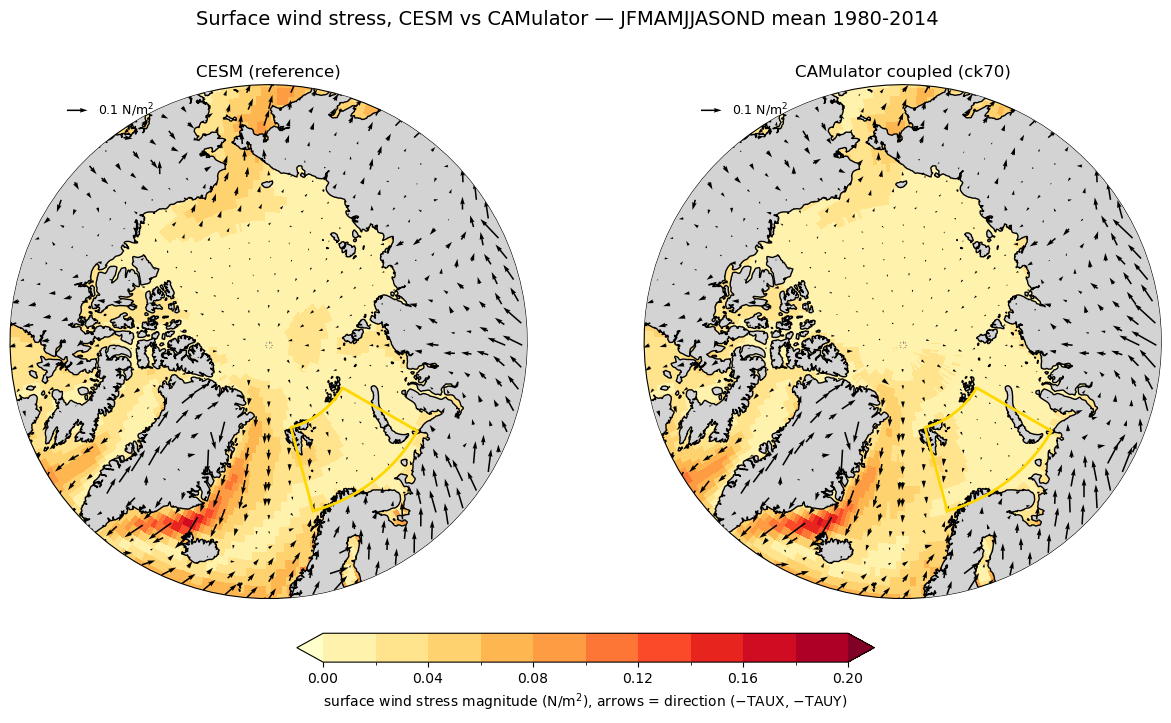

In [21]:
fig = stress.plot_atm_stress_compare(CASE, months=[1,2,3,4,5,6,7,8,9,10,11,12], years=ATM_YEARS, fig_dir=FIG_DIR)

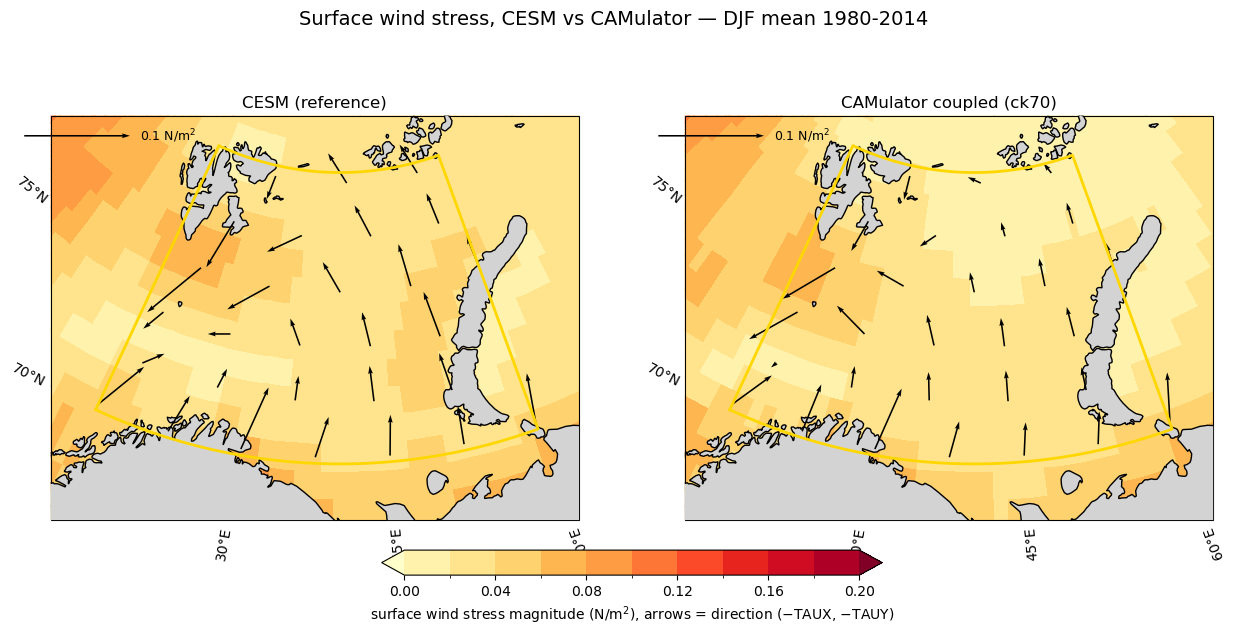

In [18]:
fig = stress.plot_atm_stress_compare(CASE, months=[12, 1, 2], years=ATM_YEARS, zoom=True, fig_dir=FIG_DIR)